In [1]:
print("Deep Learning NLP Text Classifier")
print("Project: SMS Spam Classification")

Deep Learning NLP Text Classifier
Project: SMS Spam Classification


In [2]:
import re
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Device:", device)

All libraries imported successfully!
PyTorch version: 2.14.1+cpu
Device: cpu


In [3]:
df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset loaded successfully!")

print("\nFirst five messages:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nClass distribution:")
print(df["label"].value_counts())

Dataset loaded successfully!

First five messages:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape:
(5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [4]:
import os

print(os.getcwd())
print(os.listdir())

C:\INTERNSHIP 2\task 5
['.ipynb_checkpoints', 'confusion_matrix.png', 'Deep_Learning_NLP_Text_Classifier.ipynb', 'SMSSpamCollection', 'spam_classifier.pth', 'tfidf_vectorizer.pkl', 'training_curves.png']


In [5]:
df = df.dropna()

df = df.drop_duplicates()

df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("Missing values:")
print(df.isnull().sum())

print("\nDataset after cleaning:")
print(df.head())

print("\nFinal dataset shape:")
print(df.shape)

print("\nLabel distribution:")
print(df["label"].value_counts())

Missing values:
label      0
message    0
dtype: int64

Dataset after cleaning:
   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...

Final dataset shape:
(5169, 2)

Label distribution:
label
0    4516
1     653
Name: count, dtype: int64


In [6]:
X = df["message"].astype(str)

y = df["label"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


In [7]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2),
    lowercase=True
)

X_train_vec = vectorizer.fit_transform(
    X_train
).toarray()

X_test_vec = vectorizer.transform(
    X_test
).toarray()

print("TF-IDF conversion completed!")

print("Training feature shape:", X_train_vec.shape)
print("Testing feature shape:", X_test_vec.shape)

TF-IDF conversion completed!
Training feature shape: (4135, 5000)
Testing feature shape: (1034, 5000)


In [8]:
X_train_tensor = torch.tensor(
    X_train_vec,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_vec,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

print("Training tensors created successfully!")
print("Training input shape:", X_train_tensor.shape)
print("Training target shape:", y_train_tensor.shape)

Training tensors created successfully!
Training input shape: torch.Size([4135, 5000])
Training target shape: torch.Size([4135, 1])


In [9]:
X_train_tensor, X_val_tensor, y_train_tensor, y_val_tensor = (
    train_test_split(
        X_train_tensor,
        y_train_tensor,
        test_size=0.15,
        random_state=42,
        stratify=y_train.to_numpy()
    )
)

print("Training samples:", len(X_train_tensor))
print("Validation samples:", len(X_val_tensor))
print("Testing samples:", len(X_test_tensor))

Training samples: 3514
Validation samples: 621
Testing samples: 1034


In [10]:
class SpamClassifier(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)


model = SpamClassifier(
    input_size=X_train_tensor.shape[1]
)

print(model)

SpamClassifier(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [11]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer configured!")

Loss function and optimizer configured!


In [12]:
epochs = 30
batch_size = 64
patience = 4

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())
wait = 0

for epoch in range(epochs):

    model.train()

    permutation = torch.randperm(
        len(X_train_tensor)
    )

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for start in range(
        0, len(permutation), batch_size
    ):

        indices = permutation[
            start:start + batch_size
        ]

        xb = X_train_tensor[indices]
        yb = y_train_tensor[indices]

        optimizer.zero_grad()

        logits = model(xb)

        loss = criterion(logits, yb)

        loss.backward()

        optimizer.step()

        train_loss_sum += loss.item() * len(xb)

        predictions = (
            torch.sigmoid(logits) >= 0.5
        ).float()

        train_correct += (
            predictions == yb
        ).sum().item()

        train_total += len(xb)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    model.eval()

    with torch.no_grad():

        val_logits = model(X_val_tensor)

        val_loss = criterion(
            val_logits,
            y_val_tensor
        ).item()

        val_predictions = (
            torch.sigmoid(val_logits) >= 0.5
        ).float()

        val_acc = (
            val_predictions == y_val_tensor
        ).float().mean().item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_weights = copy.deepcopy(
            model.state_dict()
        )

        wait = 0

    else:

        wait += 1

    if wait >= patience:

        print("Early stopping triggered.")

        break

model.load_state_dict(best_weights)

print("Training completed successfully!")

Epoch 01 | Train Loss: 0.2987 | Val Loss: 0.2620 | Train Accuracy: 0.9081 | Val Accuracy: 0.9227
Epoch 02 | Train Loss: 0.0759 | Val Loss: 0.1028 | Train Accuracy: 0.9926 | Val Accuracy: 0.9807
Epoch 03 | Train Loss: 0.0373 | Val Loss: 0.0744 | Train Accuracy: 0.9969 | Val Accuracy: 0.9758
Epoch 04 | Train Loss: 0.0240 | Val Loss: 0.0658 | Train Accuracy: 0.9974 | Val Accuracy: 0.9775
Epoch 05 | Train Loss: 0.0145 | Val Loss: 0.0597 | Train Accuracy: 0.9991 | Val Accuracy: 0.9807
Epoch 06 | Train Loss: 0.0108 | Val Loss: 0.0540 | Train Accuracy: 0.9989 | Val Accuracy: 0.9807
Epoch 07 | Train Loss: 0.0087 | Val Loss: 0.0540 | Train Accuracy: 0.9994 | Val Accuracy: 0.9823
Epoch 08 | Train Loss: 0.0069 | Val Loss: 0.0496 | Train Accuracy: 0.9994 | Val Accuracy: 0.9775
Epoch 09 | Train Loss: 0.0049 | Val Loss: 0.0536 | Train Accuracy: 0.9997 | Val Accuracy: 0.9807
Epoch 10 | Train Loss: 0.0051 | Val Loss: 0.0499 | Train Accuracy: 0.9997 | Val Accuracy: 0.9823
Epoch 11 | Train Loss: 0.0044 

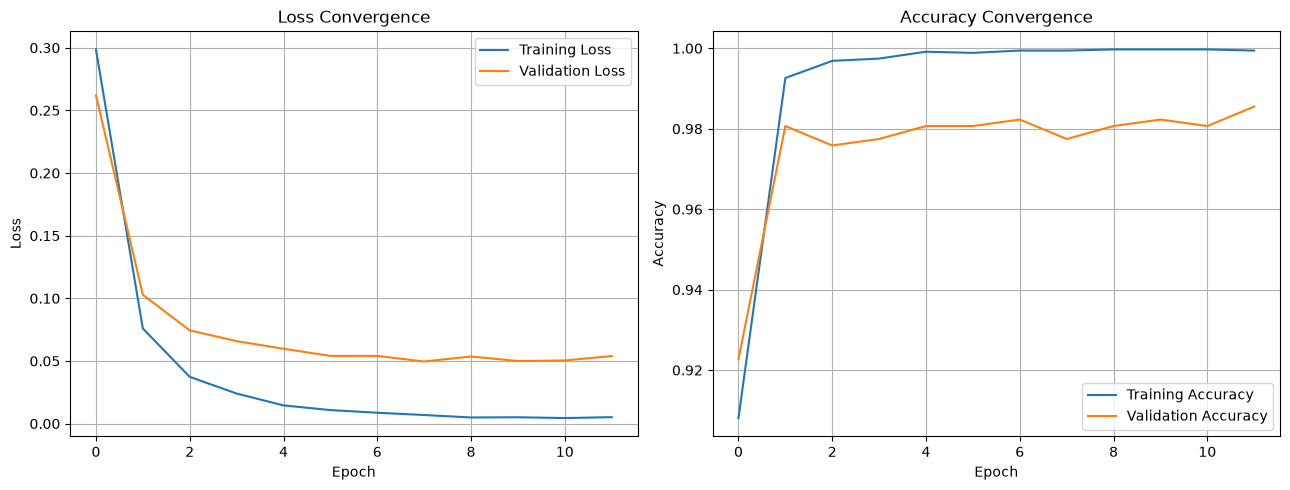

In [13]:
fig, axes = plt.subplots(
    1, 2, figsize=(13, 5)
)

axes[0].plot(
    history["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Loss Convergence")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


axes[1].plot(
    history["train_acc"],
    label="Training Accuracy"
)

axes[1].plot(
    history["val_acc"],
    label="Validation Accuracy"
)

axes[1].set_title("Accuracy Convergence")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    "training_curves.png",
    dpi=150
)

plt.show()

In [14]:
model.eval()

with torch.no_grad():

    test_logits = model(X_test_tensor)

    test_probabilities = (
        torch.sigmoid(test_logits)
        .numpy()
        .ravel()
    )

y_pred = (
    test_probabilities >= 0.5
).astype(int)

y_true = y_test.to_numpy()

print(
    "Test Accuracy:",
    accuracy_score(y_true, y_pred)
)

print("\nClassification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

Test Accuracy: 0.9845261121856866

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       903
        Spam       0.97      0.91      0.94       131

    accuracy                           0.98      1034
   macro avg       0.98      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034



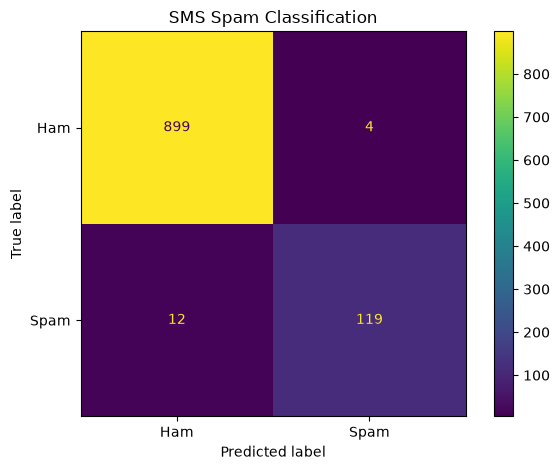

In [15]:
cm = confusion_matrix(
    y_true,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot()

plt.title("SMS Spam Classification")

plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=150
)

plt.show()

In [16]:
def predict_message(message):

    model.eval()

    message_vec = vectorizer.transform(
        [message]
    ).toarray()

    message_tensor = torch.tensor(
        message_vec,
        dtype=torch.float32
    )

    with torch.no_grad():

        logit = model(message_tensor)

        spam_probability = torch.sigmoid(
            logit
        ).item()

    if spam_probability >= 0.5:

        label = "Spam"

        confidence = spam_probability

    else:

        label = "Ham"

        confidence = 1 - spam_probability

    return {
        "Message": message,
        "Prediction": label,
        "Confidence": round(
            confidence * 100, 2
        ),
        "Spam Probability": round(
            spam_probability * 100, 2
        )
    }

In [17]:
samples = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! Claim your cash reward now!",
    "Please send me the notes from today's lecture."
]

for message in samples:

    print(predict_message(message))

    print("-" * 50)

{'Message': 'Congratulations! You have won a free prize. Call now!', 'Prediction': 'Spam', 'Confidence': 99.23, 'Spam Probability': 99.23}
--------------------------------------------------
{'Message': 'Hey, are we meeting for lunch today?', 'Prediction': 'Ham', 'Confidence': 99.66, 'Spam Probability': 0.34}
--------------------------------------------------
{'Message': 'URGENT! Claim your cash reward now!', 'Prediction': 'Spam', 'Confidence': 99.2, 'Spam Probability': 99.2}
--------------------------------------------------
{'Message': "Please send me the notes from today's lecture.", 'Prediction': 'Ham', 'Confidence': 99.74, 'Spam Probability': 0.26}
--------------------------------------------------


In [18]:
torch.save(
    model.state_dict(),
    "spam_classifier.pth"
)

joblib.dump(
    vectorizer,
    "tfidf_vectorizer.pkl"
)

print("Model saved successfully!")

Model saved successfully!
